# Classifying cancer expression vectors

In this project, we are training a neural network to identify which tissue type produced an RNA expression vector. The dataset is comprised of RNA-seq data obtained from tumors.


The data is sourced from the following link and publication:  
For a complete description of the data collection workflow see this page:
https://xenabrowser.net/datapages/?host=https://toil.xenahubs.net

And for the corresponding publication:
https://doi.org/10.1038/nbt.3772

In [1]:
# Importin necessary libraries
import sys
import numpy as np
from matplotlib import pyplot
import pandas as pd
import h5py
import os
from sklearn.model_selection import StratifiedShuffleSplit
import torch
import torch.nn as nn
from torch import optim
from torch.autograd import Variable
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset
import torch.nn.functional as F

print("USING pytorch VERSION: ", torch.__version__)

KeyboardInterrupt: 

## Loading and parsing training data
Initially, there are >50,000 genes in each expression vector, which we are reducing to a much smaller gene set for the sake of minimizing computation time. Here, the data is subsetted to only include genes from the KEGG gene set.

For a list of gene sets, check out the MSigDB collections page: http://software.broadinstitute.org/gsea/msigdb/collections.jsp

This script was adapted from Rob Currie's ingestion script: https://github.com/rcurrie/tumornormal/blob/master/genesets.ipynb

We have placed a subset of this data here for download:

https://drive.google.com/drive/folders/1pPABQDEHCddPTJAhfD6G5KyBDJiK3unQ?usp=sharing

In [ ]:
# Load the data - If using Google drive link to access data the following with connect
# to drive, authenticate using your Google account and load the data

!pip install -U -q PyDrive ## you will have install for every colab session

from pydrive.auth import GoogleAuth
from pydrive.drive import GoogleDrive
from google.colab import auth
from oauth2client.client import GoogleCredentials

# 1. Authenticate and create the PyDrive client.
auth.authenticate_user()
gauth = GoogleAuth()
gauth.credentials = GoogleCredentials.get_application_default()
drive = GoogleDrive(gauth)

#x_test: https://drive.google.com/file/d/1Cc4zEw1wANFX8S44L87Rx_EZWwCcONMW/view?usp=sharing
#x_train: https://drive.google.com/file/d/1s8VvRaUc62OYukRunV689Y9u-v_y7KRl/view?usp=sharing
#y_test: https://drive.google.com/file/d/1W4Qdr3zm5QYGP5ncMQSurrO1m05KsKQ2/view?usp=sharing
#t_train: https://drive.google.com/file/d/1UmDZ25W84DmIY4im2XHCAc5QGgNkdexD/view?usp=sharing

# 2. Now proxy the Google Drive files to a local file
x_test_import = drive.CreateFile({'id':'1Cc4zEw1wANFX8S44L87Rx_EZWwCcONMW'})
x_train_import = drive.CreateFile({'id':'1s8VvRaUc62OYukRunV689Y9u-v_y7KRl'})
y_test_import = drive.CreateFile({'id':'1W4Qdr3zm5QYGP5ncMQSurrO1m05KsKQ2'})
y_train_import = drive.CreateFile({'id':'1UmDZ25W84DmIY4im2XHCAc5QGgNkdexD'})

x_test_import.GetContentFile('x_test.npz') # x_test.npz is the file name that will be accessible in the notebook.
x_train_import.GetContentFile('x_train.npz') # x_train.npz is the file name that will be accessible in the notebook.
y_test_import.GetContentFile('y_test.npz') # y_test.npz is the file name that will be accessible in the notebook.
y_train_import.GetContentFile('y_train.npz') # y_train.npz is the file name that will be accessible in the notebook.

y_index_key = {'Adipose Tissue': 0, 'Adrenal Gland': 1, 'Adrenal gland': 2, 'Bile duct': 3, 'Bladder': 4, 'Blood': 5, 'Blood Vessel': 6, 'Bone Marrow': 7, 'Brain': 8, 'Breast': 9, 'Cervix': 10, 'Cervix Uteri': 11, 'Colon': 12, 'Endometrium': 13, 'Esophagus': 14, 'Eye': 15, 'Fallopian Tube': 16, 'Head and Neck region': 17, 'Heart': 18, 'Kidney': 19, 'Lining of body cavities': 20, 'Liver': 21, 'Lung': 22, 'Lymphatic tissue': 23, 'Muscle': 24, 'Nerve': 25, 'Ovary': 26, 'Pancreas': 27, 'Paraganglia': 28, 'Pituitary': 29, 'Prostate': 30, 'Rectum': 31, 'Salivary Gland': 32, 'Skin': 33, 'Small Intestine': 34, 'Soft tissue,Bone': 35, 'Spleen': 36, 'Stomach': 37, 'SympatheticÊNervous System': 38, 'Testis': 39, 'Thymus': 40, 'Thyroid': 41, 'Thyroid Gland': 42, 'Uterus': 43, 'Vagina': 44, 'White blood cell': 45}

for name in y_index_key:
  print(name, y_index_key[name])

Adipose Tissue 0
Adrenal Gland 1
Adrenal gland 2
Bile duct 3
Bladder 4
Blood 5
Blood Vessel 6
Bone Marrow 7
Brain 8
Breast 9
Cervix 10
Cervix Uteri 11
Colon 12
Endometrium 13
Esophagus 14
Eye 15
Fallopian Tube 16
Head and Neck region 17
Heart 18
Kidney 19
Lining of body cavities 20
Liver 21
Lung 22
Lymphatic tissue 23
Muscle 24
Nerve 25
Ovary 26
Pancreas 27
Paraganglia 28
Pituitary 29
Prostate 30
Rectum 31
Salivary Gland 32
Skin 33
Small Intestine 34
Soft tissue,Bone 35
Spleen 36
Stomach 37
SympatheticÊNervous System 38
Testis 39
Thymus 40
Thyroid 41
Thyroid Gland 42
Uterus 43
Vagina 44
White blood cell 45


## Defining a pytorch Dataset object to contain the training and testing data
We use Pytorch to handle data shuffling and batch loading, as long as the user provides a "Dataset" class. This class is just a wrapper for our data that casts the data into pytorch tensor format and returns slices of the data. In this case, our data has been stored in numpy format, which conveniently pytorch has a method for converting to their native format.

In [ ]:
class PrimarySiteDataset(Dataset):
    def __init__(self, x_path, y_path, batch_size=None):
        x = np.load(x_path)['a']
        y = np.load(y_path)['a']

        x_dtype = torch.FloatTensor
        y_dtype = torch.FloatTensor     # for MSE Loss

        self.length = x.shape[0]

        self.x_data = torch.from_numpy(x).type(x_dtype)
        self.y_data = torch.from_numpy(y).type(y_dtype)

    def __getitem__(self, index):
        return self.x_data[index], self.y_data[index]

    def __len__(self):
        return self.length

Creating train and test dataset


In [ ]:
x_train_path = "x_train.npz"
y_train_path = "y_train.npz"
x_test_path = "x_test.npz"
y_test_path = "y_test.npz"
dataset_train = PrimarySiteDataset(x_path=x_train_path,
y_path=y_train_path)
dataset_test = PrimarySiteDataset(x_path=x_test_path,
y_path=y_test_path)

In [ ]:
# Print information on the train and test datasets
print('Train datapoints: ', len(dataset_train))
print('Test datapoints: ', len(dataset_test))
print('Input features: ', len(dataset_train[1][0]))
print('Output classes: ', len(dataset_train[1][1]))

Train datapoints:  15300
Test datapoints:  3826
Input features:  5172
Output classes:  46


## Define training and test methods for the model


The train_batch function is used for running one pass of one of the datapoints through the neural network for training. It involves forward propogation of the data, calculation of the error/loss and then backward propogation to update the weight parameters.

It takes in x as the input data of the network i.e the gene expression features and y as the label class. The loss_fn input parameter is for providng a loss function for calculating the difference between the predicted outputs from our network and the actual label classes as the loss and then compute the gradient of the loss with respect to each of the weights. The optimizer is used to update the gradients based on the loss. The function returns the loss/error for the current datapoint.

In [ ]:
def train_batch(model, x, y, optimizer, loss_fn):
    ## Note, in practice pytorch can do this all for you in one step, but showing you here to be explicit

    # Run forward calculation
    y_predict = model.forward(x)

    # convert 1-hot vectors back into indices
    max_values, target_index = y.max(dim=1)
    target_index = target_index.type(torch.LongTensor)

    # Compute loss.
    loss = loss_fn(y_predict, target_index)

    # Before the backward pass, use the optimizer object to zero all of the
    # gradients for the variables it will update (which are the learnable weights
    # of the model)
    optimizer.zero_grad()

    # Backward pass: compute gradient of the loss with respect to model
    # parameters
    loss.backward()

    # Calling the step function on an Optimizer makes an update to its
    # parameters
    optimizer.step()

    return loss.data.item()

The train function uses the train_batch function above to train the model by passing the dataset through the neural network over multiple iterations i.e epochs. The loader parameter provides the input data and label classes, the optimizer and loss function are used in each epoch in the train_batch function. The epochs parameter determines the number of iterations. The function returns the losses from the entire training.

In [ ]:
def train(model, loader, optimizer, loss_fn, epochs=5):
    losses = list()

    batch_index = 0
    for e in range(epochs):
        for x, y in loader:
            loss = train_batch(model=model, x=x, y=y, optimizer=optimizer, loss_fn=loss_fn)
            losses.append(loss)
            batch_index += 1

        print("Epoch: ", e+1)
        print("Batches: ", batch_index)


    return losses

The test batch funtion is used for getting outputs for a datapoint that will be used for making predictions of it's. label classes. The function returns the output of the model.


In [ ]:
def test_batch(model, x, y):
    # run forward calculation
    y_predict = model.forward(x)

    return y, y_predict

The test funtion is used for testing all the datapoints from the test data to get the predictions.



In [ ]:
def test(model, loader):
    y_vectors = list()
    y_predict_vectors = list()

    batch_index = 0
    for x, y in loader:
        y, y_predict = test_batch(model=model, x=x, y=y)

        y_vectors.append(y.data.numpy())
        y_predict_vectors.append(y_predict.data.numpy())

        batch_index += 1

    y_predict_vector = np.concatenate(y_predict_vectors)
    y_vector = np.concatenate(y_vectors)

    return y_vector, y_predict_vector

The funtion is used for plotting the loss over the iterations

In [ ]:
def plot_loss(losses):
    fig = pyplot.gcf()
    fig.set_size_inches(8,6)
    ax = pyplot.axes()
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss")
    x_loss = list(range(len(losses)))
    pyplot.plot(x_loss, losses)
    pyplot.show()
    pyplot.close()

##Define model architecture


This class is an implementation of the neural network model that we are using. The following architecture parameters are defined here:

*   number of layers
*   size of layers
*   activation function

In [ ]:
class ShallowLinear(nn.Module):
    '''
    A simple, general purpose, fully connected network
    '''
    def __init__(self):
        # Perform initialization of the pytorch superclass
        super(ShallowLinear, self).__init__()

        # Define network layer dimensions
        D_in, H1, H2, D_out = [5172, 15, 15, 46]    # These numbers correspond to each layer: [input, hidden_1, output]

        # Define layer types
        self.linear1 = nn.Linear(D_in, H1)
        self.linear2 = nn.Linear(H1, H2)
        self.linear3 = nn.Linear(H2, D_out)

    def forward(self, x):
        '''
        This method defines the network layering and activation functions
        '''
        x = self.linear1(x) # hidden layer
        x = torch.relu(x)       # activation function
        x = self.linear2(x) # hidden layer
        x = torch.relu(x)       # activation function
        y_prime = self.linear3(x) # output layer
        #y_prime = F.softmax(y_prime, dim=1)

        return y_prime


## Method to define hyperparameters, train, and test


Here we define the following parameters for training:

* batch size
* learning rate
* optimizer
* loss function

In [ ]:
def run(dataset_train, dataset_test, batch_size_train = 5, n_epochs = 15):
    # Batch size is the number of training examples used to calculate each iteration's gradient


    data_loader_train = DataLoader(dataset=dataset_train, batch_size=batch_size_train, shuffle=True)
    data_loader_test = DataLoader(dataset=dataset_test, batch_size=len(dataset_test), shuffle=False)

    # Define the hyperparameters
    learning_rate = 5e-5
    shallow_model = ShallowLinear()

    # Initialize the optimizer with above parameters
    optimizer = optim.Adam(shallow_model.parameters(), lr=learning_rate)

    # Define the loss function
    loss_fn = nn.CrossEntropyLoss()  # mean squared error

    # Train and get the resulting loss per iteration
    loss = train(model=shallow_model, loader=data_loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=n_epochs)

    # Test and get the resulting predicted y values
    y_vector, y_predict_vector = test(model=shallow_model, loader=data_loader_test)

    return loss, y_vector, y_predict_vector


## Training and Testing the model

In [ ]:
losses, y_vector, y_predict = run(dataset_train=dataset_train, dataset_test=dataset_test)  # Put it all together and train a model

Epoch:  1
Batches:  3060
Epoch:  2
Batches:  6120
Epoch:  3
Batches:  9180
Epoch:  4
Batches:  12240
Epoch:  5
Batches:  15300
Epoch:  6
Batches:  18360
Epoch:  7
Batches:  21420
Epoch:  8
Batches:  24480
Epoch:  9
Batches:  27540
Epoch:  10
Batches:  30600
Epoch:  11
Batches:  33660
Epoch:  12
Batches:  36720
Epoch:  13
Batches:  39780
Epoch:  14
Batches:  42840
Epoch:  15
Batches:  45900


In [ ]:
print("Final loss:", sum(losses[-1530:])/100)  # Report the loss

Final loss: 1.9319439683083328


##Assessing the performance (Part 3)

In [ ]:
# Shape of the y vector and predict vectors
print(y_vector.shape)
print(y_predict.shape)

#Table of the values of the first one
df = pd.DataFrame({'y_vector': y_vector[0], "y_predict": y_predict[0]})
print(df)

(3826, 46)
(3826, 46)
    y_vector  y_predict
0        0.0 -19.723766
1        0.0 -20.680286
2        0.0 -13.449805
3        0.0  -4.606933
4        0.0 -13.812986
5        0.0 -27.229319
6        0.0  -7.501681
7        0.0 -35.235138
8        1.0  13.686597
9        0.0   1.685083
10       0.0  -7.895308
11       0.0 -19.326281
12       0.0   0.416931
13       0.0 -13.392988
14       0.0 -18.469522
15       0.0 -15.260780
16       0.0 -11.342590
17       0.0  -0.664066
18       0.0  -4.467865
19       0.0 -14.261443
20       0.0 -21.174820
21       0.0  -1.842523
22       0.0  -9.413083
23       0.0 -31.235996
24       0.0 -21.620499
25       0.0  -6.970248
26       0.0 -26.738245
27       0.0   0.790585
28       0.0  -0.969397
29       0.0   5.387879
30       0.0 -12.112942
31       0.0  -2.682134
32       0.0   1.731714
33       0.0  -4.429846
34       0.0  -9.304608
35       0.0  -4.635014
36       0.0 -29.489878
37       0.0 -11.769692
38       0.0  -0.272173
39       0.0 -10.3

In [ ]:
real_indexes = [np.argmax(y) for y in y_vector]
predicted_indexes = [np.argmax(y) for y in y_predict]
print(len(real_indexes))
print(len(predicted_indexes))

print(real_indexes)
print(predicted_indexes)

3826
3826
[8, 5, 45, 21, 19, 0, 33, 8, 26, 22, 35, 33, 9, 8, 8, 45, 19, 12, 5, 19, 21, 9, 14, 18, 44, 40, 25, 30, 4, 18, 45, 9, 33, 22, 14, 27, 21, 25, 37, 25, 14, 5, 17, 42, 8, 21, 33, 19, 33, 4, 14, 45, 42, 42, 8, 37, 39, 14, 33, 22, 31, 18, 19, 0, 19, 29, 42, 9, 22, 37, 30, 28, 6, 9, 24, 22, 5, 19, 37, 8, 35, 21, 42, 8, 9, 5, 13, 37, 19, 41, 35, 43, 39, 45, 45, 19, 44, 12, 22, 22, 8, 9, 10, 30, 22, 7, 8, 14, 33, 39, 26, 18, 17, 45, 37, 9, 19, 19, 30, 10, 37, 8, 13, 40, 33, 8, 25, 23, 8, 31, 42, 24, 5, 33, 45, 21, 45, 33, 42, 30, 33, 26, 24, 19, 9, 19, 39, 19, 26, 22, 8, 8, 25, 37, 12, 22, 4, 22, 22, 25, 12, 12, 37, 38, 19, 22, 0, 9, 17, 4, 17, 9, 5, 5, 22, 10, 9, 22, 9, 10, 9, 9, 33, 10, 9, 24, 17, 19, 13, 21, 4, 22, 8, 24, 5, 26, 34, 9, 43, 33, 18, 42, 22, 1, 12, 9, 30, 17, 6, 17, 38, 37, 21, 14, 42, 17, 34, 12, 8, 43, 14, 12, 42, 42, 3, 8, 42, 22, 38, 19, 8, 22, 6, 6, 12, 21, 22, 8, 26, 0, 21, 26, 37, 33, 12, 22, 29, 0, 39, 13, 40, 12, 30, 9, 30, 8, 37, 23, 21, 41, 4, 17, 13, 33, 

In [ ]:
def accuracy(true_classes, predicted_classes):
  correct = 0
  n = len(true_classes)
  for i in range(n):
    if predicted_classes[i] == true_classes[i]:
      correct += 1

  return (correct/n) * 100


print(accuracy(real_indexes, predicted_indexes))

95.21693674856246


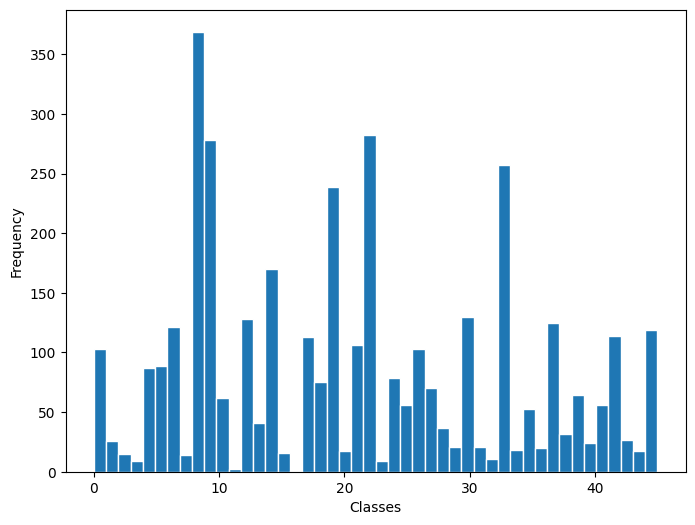

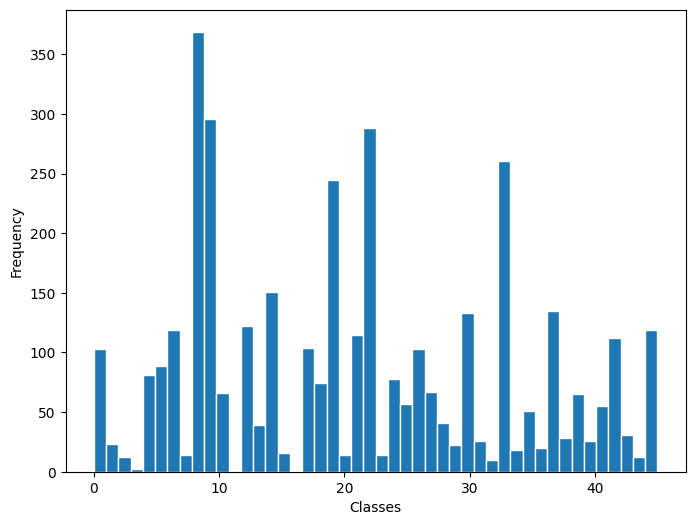

In [ ]:
def class_histogram(class_vector):
  fig = pyplot.gcf()
  fig.set_size_inches(8,6)
  ax = pyplot.axes()
  ax.set_xlabel("Classes")
  ax.set_ylabel("Frequency")
  pyplot.hist(class_vector, bins = 46, edgecolor='white')
  pyplot.show()
  pyplot.close()

class_histogram(real_indexes)
class_histogram(predicted_indexes)

## Confusion matrix (Part 5)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(real_indexes, predicted_indexes)
classes = list(y_index_key.keys())
cm_df = pd.DataFrame(cm, index=classes, columns=classes)

# Display confusion matrix as DataFrame
print("Confusion Matrix:")
cm_df

Confusion Matrix:


,Adipose Tissue,Adrenal Gland,Adrenal gland,Bile duct,Bladder,Blood,Blood Vessel,Bone Marrow,Brain,Breast,...,Spleen,Stomach,SympatheticÊNervous System,Testis,Thymus,Thyroid,Thyroid Gland,Uterus,Vagina,White blood cell
Adipose Tissue,97,0,0,0,0,0,1,0,0,3,...,0,0,0,0,0,0,0,0,0,0
Adrenal Gland,0,23,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Adrenal gland,0,0,10,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bile duct,0,0,0,2,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
Bladder,0,0,0,0,80,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
Blood,0,0,0,0,0,89,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Blood Vessel,2,0,0,0,0,0,117,0,0,2,...,0,0,0,0,0,0,0,0,0,0
Bone Marrow,0,0,0,0,0,0,0,14,0,0,...,0,0,0,0,0,0,0,0,0,0
Brain,0,0,0,0,0,0,0,0,368,1,...,0,0,0,0,0,0,0,0,0,0
Breast,0,0,0,0,0,0,0,0,0,277,...,0,0,0,0,0,0,0,0,0,0


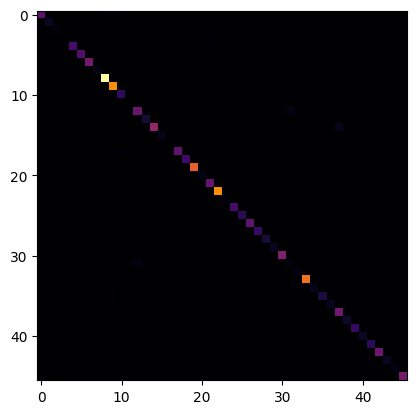

In [ ]:
pyplot.imshow(cm, cmap='inferno')

We also want to find out which classes were most confusing for the model and the classification report so we can see accuracies for each class.

In [ ]:
# Find classes where the value in the matrix is large and the classes are not the same
confused_classes = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if i != j and cm[i][j] > 5:
            confused_classes.append((i, j, cm[i][j]))

for actual, predicted, instances in confused_classes:
    print(f"Actual Class: {classes[actual]},     Predicted Class: {classes[predicted]},       Incorrect instances: {instances}")

Actual Class: Colon,     Predicted Class: Rectum,       Incorrect instances: 15
Actual Class: Esophagus,     Predicted Class: Stomach,       Incorrect instances: 19
Actual Class: Rectum,     Predicted Class: Colon,       Incorrect instances: 12
Actual Class: Soft tissue,Bone,     Predicted Class: Breast,       Incorrect instances: 6


In [ ]:
from sklearn.metrics import classification_report

classes = list(y_index_key.keys())
print(classification_report(real_indexes, predicted_indexes, target_names=classes, zero_division = 0))

                            precision    recall  f1-score   support

            Adipose Tissue       0.94      0.94      0.94       103
             Adrenal Gland       1.00      0.88      0.94        26
             Adrenal gland       0.83      0.67      0.74        15
                 Bile duct       1.00      0.22      0.36         9
                   Bladder       0.99      0.92      0.95        87
                     Blood       1.00      1.00      1.00        89
              Blood Vessel       0.98      0.97      0.97       121
               Bone Marrow       1.00      1.00      1.00        14
                     Brain       1.00      1.00      1.00       369
                    Breast       0.94      1.00      0.97       278
                    Cervix       0.89      0.95      0.92        62
              Cervix Uteri       0.00      0.00      0.00         2
                     Colon       0.89      0.85      0.87       128
               Endometrium       0.90      0.85

We want to see the class frequency of the confused classes to understand how frequency plays a part in model performance.

In [ ]:
from collections import Counter

confused_class = "Rectum"
confused_class_index = y_index_key[confused_class]

counter_train = Counter(np.argmax(label).item() for _, label in dataset_train)
counter_test = Counter(np.argmax(label).item() for _, label in dataset_test)

num_instances_train = counter_train[confused_class_index]
num_instances_test = counter_test[confused_class_index]

print("Number of examples in the training dataset", confused_class, num_instances_train)
print("Number of instances in the testing dataset", confused_class, num_instances_test)

Number of examples in the training dataset Rectum 82
Number of instances in the testing dataset Rectum 21


In [ ]:

confused_class = "Colon"
confused_class_index = y_index_key[confused_class]

num_instances_train = counter_train[confused_class_index]
num_instances_test = counter_test[confused_class_index]

print("Number of examples in the training dataset", confused_class, num_instances_train)
print("Number of instances in the testing dataset", confused_class, num_instances_test)

Number of examples in the training dataset Colon 511
Number of instances in the testing dataset Colon 128


#Assignment Written Questions

##Part1

**Questions 1: How many training examples are in the dataset?**

 Out of a total of 19126 datapoint, 15300 are training datapoints

<br>

**Questions 2: What proportion (%) of the full dataset has been set aside for testing?**

About 20% of the full dataset has been set aside for testing

<br>

**Questions 3: How many gene expression values will be used as input to classify each sample in the dataset?**

  5172 gene expression values are being used as input features

<br>

**Questions 4: How many tissue types are there in the data labels?**

  There are 46 tissue types

<br>

**Questions 5: When performing classification with a neural network, the output vector is an array with n variables, where each variable describes the probability that your input belongs to one class in your classification problem. Based on this information, what should be the size of your output layer in the neural network??**

  the output layer should have n=46 nodes

<br>

**Questions 6: How will you know which index in the output corresponds to which tissue type once you feed your data into the model and get your output?**

  We change the classes into numerical classes from 0-45 when preprocessing our data. The y_index_key variable stores which index corresponds to each type of tissue.

## Part 2

Flowchart Image: https://drive.google.com/file/d/1LIYKeQXJvr4fZDYGgtptuNSWb96EjFL9/view?usp=sharing


## Part 3



**1. Perform some changes to your model architecture and training parameters until your final loss is no longer undefined (nan). Once your model consistently obtains a reasonable loss (usually below 1) you can start working on assessing its performance. Describe the changes you made.**

<br>

To manually test with the model, we can experiment with changing around the model parameters like:
- no. of hidden layers
- size of hidden layers
- Activation function

and the hyper parameters like:
- Learning rate
- Epochs
- batch_size
- Optimizer

We experiment with changing the epochs between 5, 10 and 20, the batch_size between 8, 10 and 15


Loss with batch_size = 10 and epochs = 10 and Learning rate 1e-2 was:
-  0.3211214542761445

Loss with batch_size = 8 and epochs = 5 Learning rate 1e-2 was:
- 0.3164579813927412

Loss with batch_size = 8 and epochs = 5 Learning rate 5e-5 was:
- 0.1945287654924723

Since, we are getting a reasonable final loss for now (less than 1), we don't need to change the rest parameters yet. We will assess it on test data and improve performancce in the upcoming parts.

**2. Print the shapes of these arrays to ensure they are exactly the same dimensions. What are their dimensions?**

Both are 3826 vectors of dimension 46

**3. Do these match your test set size from part 1?**

Yes they do. We had 3826 datapoints for our test datapoints with 46 tissue types.

**4. Make a table of the first training example with the following format, showing all the rows (the one below is shortened):**



```
      y_vector  y_predict
0        0.0   0.050211
1        0.0   0.004098
2        0.0   0.001959
3        0.0   0.000239
4        0.0   0.015151
5        0.0  -0.015704
6        0.0   0.014160
7        0.0   0.004949
8        1.0   0.140462
9        0.0   0.078751
10       0.0   0.025666
11       0.0   0.013153
12       0.0   0.046455
13       0.0   0.010869
14       0.0   0.053729
15       0.0  -0.002429
16       0.0   0.000025
17       0.0   0.030853
18       0.0  -0.014512
19       0.0   0.070296
20       0.0   0.002733
21       0.0   0.021358
22       0.0   0.088416
23       0.0  -0.000946
24       0.0   0.031211
25       0.0   0.007005
26       0.0   0.030711
27       0.0   0.014807
28       0.0   0.006626
29       0.0   0.008748
30       0.0   0.025777
31       0.0   0.000641
32       0.0   0.005275
33       0.0   0.055127
34       0.0   0.004660
35       0.0   0.000132
36       0.0   0.003241
37       0.0   0.045407
38       0.0   0.017134
39       0.0   0.040510
40       0.0   0.007216
41       0.0   0.001840
42       0.0   0.011505
43       0.0   0.012034
44       0.0   0.004881
45       0.0   0.015438
```



**5. Print the shape of your argmax vectors to verify they have n entries. Write the first value of y_argmax and y_predict_argmax and compare them to the table you made in #4. Does the relationship between these values and your #4 values make sense. Do you expect the y_predict argmax to match your truth set?**


Yes they both have 3826 entries. For both the first value is 8. It makes sense since in #4 we see that the 8th class has value '1' in y_vector which means it belongs to that class. And in our values of y_predict the 8th index did have the highest value meaning highest probability for it to be in that class. We would want our values to match since that would show our model is working well however our model is not too good right now so I would not expect them to match too much.

**6. What is your overall classification accuracy? It’s expected that it won’t be great at this stage.**

Initially it was at 11% but after changing around the parameters, I started to get around 47% accuracy.  

**7. Plot a histogram of your argmax values for y, and for predicted y. How do they compare? In which scenarios would you expect your predicted distribution to match or not match your true distribution?**

Since our accuracy is not too good at the moment, we do not expect the histograms to match the true distrubution much. Incases where it predicts the right outcome of classes, we would see a much closer match but for classes where it did not predict correctly, we would see different distributions.

Initially the histogram of y_predict was only showing bars for two classes but after changing around the parameters, I got a more spread out distribution. But it is still not close to the distribution of the true vectors. We show the histogram we had below (before changes for part4 and 5 were made).

In [ ]:
part_3_indexes = [8, 45, 42, 14, 22, 6, 33, 8, 42, 22, 14, 33, 6, 8, 8, 45, 22, 14, 42, 22, 42, 9, 14, 18, 45, 14, 30, 30, 14, 18, 45, 9, 33, 22, 14, 45, 42, 30, 42, 30, 14, 14, 14, 6, 8, 42, 33, 22, 33, 14, 14, 45, 42, 42, 8, 14, 14, 14, 33, 22, 14, 18, 22, 6, 22, 14, 14, 9, 22, 14, 30, 42, 6, 9, 24, 22, 42, 22, 42, 8, 6, 42, 42, 8, 9, 45, 14, 42, 22, 14, 14, 42, 14, 42, 45, 22, 14, 14, 22, 22, 8, 9, 19, 30, 22, 14, 8, 14, 33, 14, 14, 18, 14, 45, 14, 9, 22, 22, 30, 14, 14, 8, 14, 14, 33, 8, 30, 6, 8, 14, 42, 24, 45, 33, 45, 45, 14, 33, 14, 30, 33, 14, 24, 22, 9, 22, 14, 22, 14, 22, 8, 8, 30, 14, 14, 22, 19, 22, 22, 30, 14, 22, 14, 14, 0, 22, 6, 9, 42, 14, 14, 9, 30, 45, 22, 14, 9, 22, 9, 14, 9, 9, 33, 14, 9, 24, 14, 22, 14, 45, 14, 22, 8, 24, 42, 14, 14, 9, 14, 33, 18, 45, 22, 14, 14, 9, 30, 14, 6, 14, 14, 14, 45, 14, 14, 14, 14, 14, 8, 14, 14, 14, 42, 14, 42, 8, 14, 22, 14, 22, 8, 22, 6, 6, 14, 6, 22, 8, 14, 6, 42, 14, 14, 33, 14, 22, 42, 6, 14, 19, 14, 14, 30, 9, 30, 8, 14, 0, 45, 14, 14, 14, 14, 33, 42, 22, 33, 30, 8, 22, 9, 22, 14, 30, 22, 42, 22, 22, 42, 6, 14, 14, 45, 6, 14, 8, 45, 14, 42, 45, 22, 45, 33, 45, 14, 33, 18, 9, 14, 42, 8, 42, 6, 22, 9, 14, 9, 9, 9, 45, 14, 9, 14, 9, 22, 33, 22, 42, 30, 45, 9, 42, 18, 14, 14, 14, 8, 24, 6, 14, 45, 33, 14, 33, 45, 14, 6, 14, 14, 6, 14, 8, 33, 30, 9, 14, 22, 14, 30, 14, 33, 33, 8, 14, 8, 14, 45, 18, 14, 14, 14, 42, 14, 30, 33, 6, 14, 22, 14, 14, 8, 14, 45, 33, 9, 14, 8, 22, 14, 6, 22, 6, 14, 14, 6, 35, 33, 33, 8, 14, 8, 22, 45, 6, 42, 14, 42, 14, 30, 42, 18, 24, 45, 14, 19, 14, 22, 14, 14, 14, 22, 45, 14, 45, 33, 9, 45, 30, 14, 33, 42, 22, 30, 22, 9, 45, 14, 22, 8, 14, 8, 30, 6, 30, 14, 14, 9, 22, 14, 33, 42, 14, 14, 8, 45, 30, 8, 45, 22, 14, 14, 22, 19, 22, 9, 22, 14, 14, 45, 30, 22, 14, 22, 14, 14, 18, 9, 14, 8, 42, 14, 24, 33, 9, 22, 45, 14, 22, 45, 14, 30, 9, 8, 14, 22, 14, 18, 14, 6, 19, 22, 24, 9, 8, 22, 42, 9, 30, 14, 14, 30, 42, 22, 33, 14, 22, 42, 14, 22, 8, 42, 14, 6, 8, 19, 30, 14, 30, 22, 14, 22, 22, 30, 9, 8, 14, 9, 30, 9, 14, 22, 18, 14, 22, 14, 14, 9, 0, 22, 22, 14, 14, 42, 8, 6, 14, 22, 8, 33, 8, 8, 19, 42, 18, 8, 22, 33, 8, 42, 14, 22, 14, 45, 22, 33, 14, 14, 8, 8, 6, 14, 22, 33, 14, 22, 33, 22, 33, 8, 45, 6, 9, 6, 9, 14, 14, 42, 45, 14, 18, 8, 6, 45, 14, 9, 8, 6, 14, 8, 14, 42, 42, 9, 14, 30, 22, 14, 14, 9, 22, 24, 33, 45, 42, 22, 45, 30, 14, 14, 9, 22, 22, 8, 45, 42, 14, 6, 8, 9, 14, 14, 14, 19, 8, 22, 14, 14, 22, 30, 14, 30, 30, 14, 22, 22, 9, 6, 24, 9, 22, 33, 14, 24, 9, 24, 30, 14, 14, 42, 22, 14, 9, 33, 8, 8, 14, 6, 14, 22, 6, 22, 22, 22, 22, 42, 42, 22, 14, 14, 6, 8, 14, 33, 14, 8, 19, 22, 30, 42, 33, 14, 45, 6, 30, 8, 22, 14, 45, 6, 14, 6, 22, 22, 6, 22, 8, 30, 42, 22, 8, 6, 9, 22, 33, 22, 45, 22, 14, 14, 14, 24, 22, 14, 9, 14, 9, 14, 14, 14, 14, 14, 24, 14, 24, 6, 14, 24, 24, 33, 14, 14, 14, 22, 9, 6, 14, 14, 6, 9, 14, 22, 22, 22, 19, 33, 8, 6, 42, 14, 14, 14, 6, 42, 45, 14, 33, 6, 18, 6, 14, 8, 14, 14, 14, 14, 30, 33, 14, 22, 42, 6, 30, 14, 42, 22, 45, 24, 22, 6, 9, 9, 30, 22, 14, 8, 30, 45, 8, 42, 42, 8, 45, 45, 24, 8, 8, 8, 14, 14, 30, 14, 42, 6, 42, 8, 45, 33, 45, 8, 14, 14, 24, 14, 9, 33, 42, 6, 22, 8, 14, 22, 14, 30, 14, 22, 14, 14, 8, 30, 9, 6, 8, 14, 14, 45, 14, 14, 30, 22, 19, 14, 30, 30, 14, 14, 19, 22, 8, 14, 33, 22, 9, 18, 6, 45, 14, 22, 14, 14, 8, 14, 14, 6, 14, 33, 8, 0, 14, 22, 33, 8, 22, 8, 22, 30, 30, 22, 14, 45, 14, 30, 22, 22, 8, 14, 14, 24, 14, 9, 45, 8, 14, 14, 18, 14, 14, 8, 42, 30, 8, 6, 22, 14, 8, 14, 33, 45, 45, 33, 6, 22, 14, 22, 14, 14, 9, 14, 22, 45, 8, 42, 42, 45, 8, 22, 8, 14, 30, 33, 33, 42, 6, 14, 33, 24, 14, 14, 22, 42, 22, 14, 45, 42, 30, 22, 45, 22, 14, 22, 22, 8, 22, 14, 22, 42, 9, 42, 9, 9, 22, 8, 5, 14, 14, 42, 9, 14, 30, 8, 33, 14, 30, 19, 6, 33, 22, 42, 14, 22, 14, 42, 14, 8, 22, 8, 30, 6, 8, 22, 14, 8, 18, 6, 9, 30, 22, 22, 14, 42, 14, 30, 45, 45, 9, 19, 14, 14, 8, 22, 18, 22, 14, 42, 6, 14, 42, 24, 19, 9, 14, 14, 22, 33, 45, 9, 22, 14, 33, 42, 30, 14, 22, 8, 14, 30, 42, 22, 22, 22, 42, 30, 14, 45, 33, 19, 33, 33, 35, 24, 30, 6, 30, 33, 6, 6, 14, 45, 14, 30, 8, 9, 33, 14, 33, 22, 14, 45, 30, 8, 22, 30, 6, 33, 6, 33, 33, 42, 14, 45, 30, 14, 9, 42, 22, 19, 30, 33, 14, 14, 30, 14, 42, 14, 14, 9, 9, 9, 8, 22, 33, 9, 6, 33, 22, 6, 35, 6, 8, 22, 30, 22, 14, 14, 14, 30, 14, 33, 14, 14, 42, 6, 14, 30, 8, 14, 14, 33, 14, 22, 14, 14, 42, 24, 6, 35, 8, 14, 33, 14, 9, 14, 14, 6, 45, 42, 9, 14, 6, 42, 14, 14, 14, 45, 8, 22, 14, 6, 18, 22, 45, 6, 45, 14, 42, 6, 6, 9, 9, 42, 33, 8, 30, 33, 45, 14, 22, 19, 22, 22, 6, 45, 14, 18, 22, 22, 14, 30, 18, 22, 14, 6, 14, 33, 24, 22, 6, 22, 8, 14, 18, 42, 8, 42, 6, 14, 22, 6, 18, 9, 22, 8, 22, 33, 22, 6, 45, 14, 6, 33, 9, 30, 8, 22, 8, 33, 6, 22, 22, 42, 22, 14, 6, 45, 18, 14, 33, 8, 45, 22, 14, 22, 22, 18, 45, 33, 14, 22, 8, 8, 9, 9, 30, 33, 33, 18, 14, 6, 22, 14, 22, 22, 33, 30, 9, 9, 14, 14, 22, 45, 14, 22, 14, 42, 33, 14, 42, 18, 24, 14, 22, 8, 8, 22, 42, 22, 9, 6, 6, 30, 6, 6, 33, 9, 42, 14, 8, 14, 9, 22, 42, 33, 14, 14, 33, 42, 33, 8, 45, 6, 45, 22, 45, 45, 9, 14, 8, 6, 14, 14, 42, 42, 22, 30, 45, 22, 8, 45, 14, 14, 14, 45, 22, 8, 6, 14, 45, 33, 9, 14, 30, 45, 42, 33, 14, 22, 33, 22, 22, 14, 35, 33, 14, 24, 22, 14, 14, 19, 45, 22, 33, 45, 22, 22, 14, 30, 24, 22, 33, 22, 33, 14, 8, 8, 14, 22, 9, 45, 22, 8, 9, 14, 8, 42, 30, 14, 22, 9, 22, 30, 9, 22, 14, 6, 22, 14, 22, 45, 14, 33, 14, 45, 14, 42, 22, 14, 30, 9, 33, 14, 22, 42, 14, 45, 30, 42, 22, 18, 22, 45, 22, 22, 14, 33, 30, 14, 6, 22, 45, 6, 22, 14, 6, 6, 14, 9, 33, 14, 14, 45, 30, 45, 42, 19, 6, 42, 6, 33, 42, 6, 42, 14, 14, 22, 8, 14, 30, 6, 33, 6, 8, 14, 45, 30, 14, 9, 30, 24, 14, 33, 14, 9, 14, 30, 22, 22, 19, 33, 14, 14, 14, 14, 33, 18, 42, 8, 9, 6, 8, 30, 9, 9, 14, 9, 30, 33, 14, 9, 14, 9, 8, 6, 42, 22, 24, 22, 19, 24, 9, 14, 24, 45, 45, 14, 14, 14, 45, 14, 19, 14, 14, 42, 14, 42, 22, 8, 8, 42, 9, 45, 45, 33, 45, 42, 42, 14, 24, 22, 6, 14, 22, 33, 14, 8, 6, 14, 8, 14, 22, 33, 22, 33, 22, 6, 14, 30, 33, 6, 8, 9, 19, 8, 6, 33, 14, 8, 45, 33, 9, 14, 22, 22, 30, 22, 24, 9, 8, 22, 9, 8, 33, 42, 14, 33, 14, 33, 6, 22, 22, 14, 14, 45, 8, 22, 42, 45, 14, 14, 8, 45, 30, 6, 14, 14, 22, 30, 22, 14, 14, 45, 9, 42, 6, 8, 8, 14, 8, 22, 14, 30, 6, 14, 6, 14, 6, 22, 18, 8, 22, 9, 9, 14, 42, 42, 18, 6, 6, 33, 45, 14, 24, 9, 6, 42, 14, 6, 22, 6, 8, 22, 42, 14, 14, 22, 45, 18, 14, 14, 45, 22, 42, 8, 22, 33, 45, 14, 8, 24, 22, 14, 22, 14, 8, 14, 30, 8, 45, 14, 14, 33, 8, 14, 8, 45, 42, 14, 6, 45, 24, 22, 6, 9, 14, 6, 6, 19, 14, 22, 45, 14, 42, 14, 22, 22, 6, 8, 14, 22, 8, 14, 33, 33, 33, 22, 9, 8, 9, 22, 30, 45, 22, 18, 6, 14, 45, 14, 9, 9, 14, 45, 45, 8, 9, 14, 30, 14, 14, 33, 8, 19, 14, 14, 8, 8, 14, 14, 19, 14, 22, 22, 9, 42, 8, 33, 22, 45, 14, 8, 33, 14, 22, 6, 45, 22, 8, 8, 14, 45, 22, 9, 45, 45, 8, 9, 22, 14, 8, 45, 8, 14, 14, 22, 9, 45, 8, 14, 22, 8, 14, 8, 42, 14, 30, 24, 8, 6, 6, 9, 14, 14, 33, 30, 9, 45, 14, 14, 19, 14, 22, 6, 6, 42, 6, 6, 45, 33, 22, 45, 14, 8, 6, 8, 33, 33, 33, 8, 8, 8, 45, 33, 8, 19, 22, 22, 14, 14, 14, 18, 8, 14, 22, 14, 30, 22, 22, 14, 14, 9, 9, 14, 8, 24, 30, 14, 14, 14, 22, 8, 9, 22, 6, 42, 6, 14, 22, 22, 30, 9, 42, 8, 42, 14, 42, 30, 18, 14, 45, 45, 33, 30, 14, 14, 14, 14, 30, 22, 42, 6, 42, 9, 22, 14, 30, 9, 22, 8, 14, 6, 14, 6, 30, 14, 24, 14, 14, 14, 14, 33, 9, 8, 33, 22, 42, 14, 30, 14, 6, 22, 19, 8, 30, 9, 14, 45, 14, 14, 9, 14, 6, 22, 22, 14, 42, 6, 14, 45, 42, 22, 45, 6, 6, 8, 14, 22, 14, 8, 45, 14, 24, 8, 24, 22, 14, 9, 42, 9, 45, 9, 22, 33, 22, 6, 30, 33, 45, 8, 33, 22, 45, 6, 8, 33, 14, 14, 14, 14, 14, 14, 8, 9, 42, 9, 8, 8, 8, 45, 14, 14, 18, 18, 45, 22, 9, 14, 14, 33, 45, 14, 22, 9, 14, 0, 14, 42, 14, 14, 22, 19, 33, 45, 14, 14, 22, 14, 6, 14, 42, 14, 22, 30, 14, 45, 19, 22, 14, 22, 8, 8, 30, 6, 22, 30, 19, 14, 30, 14, 33, 8, 14, 42, 22, 22, 45, 14, 14, 9, 33, 8, 24, 14, 14, 14, 30, 22, 8, 14, 22, 14, 14, 14, 30, 14, 45, 24, 6, 45, 22, 14, 9, 33, 30, 18, 14, 9, 9, 6, 14, 42, 14, 9, 14, 45, 14, 30, 22, 14, 24, 22, 8, 9, 45, 22, 14, 14, 22, 14, 14, 30, 14, 45, 22, 14, 14, 33, 14, 33, 14, 14, 22, 8, 30, 42, 8, 45, 45, 24, 33, 22, 45, 33, 33, 30, 18, 8, 42, 14, 33, 22, 8, 14, 14, 45, 14, 6, 24, 14, 14, 42, 45, 9, 14, 14, 14, 30, 14, 6, 22, 45, 45, 45, 45, 14, 22, 18, 6, 22, 33, 8, 33, 8, 33, 9, 22, 33, 14, 14, 22, 14, 30, 14, 30, 8, 14, 42, 14, 14, 22, 42, 22, 22, 8, 14, 14, 33, 45, 45, 22, 6, 35, 8, 19, 6, 24, 22, 6, 22, 33, 9, 42, 9, 9, 42, 33, 8, 8, 33, 5, 42, 22, 19, 14, 42, 22, 30, 22, 33, 8, 14, 45, 14, 6, 8, 33, 14, 14, 0, 14, 42, 6, 22, 30, 8, 24, 33, 14, 6, 18, 33, 22, 22, 45, 6, 30, 33, 22, 30, 45, 22, 8, 45, 14, 14, 33, 42, 33, 42, 22, 24, 45, 14, 0, 22, 42, 24, 6, 14, 24, 24, 22, 24, 14, 14, 45, 22, 22, 42, 33, 14, 45, 33, 22, 22, 14, 19, 14, 22, 33, 42, 22, 14, 14, 14, 42, 33, 9, 14, 22, 6, 14, 30, 9, 22, 14, 8, 8, 14, 6, 22, 45, 14, 45, 22, 14, 14, 22, 6, 22, 14, 22, 9, 22, 22, 14, 14, 14, 22, 9, 42, 45, 18, 22, 19, 22, 14, 45, 14, 14, 14, 33, 14, 22, 45, 9, 45, 22, 14, 30, 8, 22, 33, 9, 8, 42, 33, 19, 8, 22, 22, 42, 14, 30, 22, 18, 6, 14, 8, 8, 14, 6, 14, 18, 14, 45, 9, 42, 30, 42, 42, 22, 8, 9, 9, 14, 22, 33, 14, 22, 14, 0, 22, 14, 14, 14, 14, 30, 42, 9, 33, 22, 9, 9, 9, 18, 9, 8, 45, 14, 6, 42, 45, 9, 33, 14, 6, 45, 22, 14, 33, 14, 14, 33, 6, 9, 14, 6, 14, 22, 22, 14, 8, 22, 19, 22, 30, 22, 22, 42, 42, 14, 9, 22, 14, 42, 14, 33, 42, 30, 22, 19, 14, 14, 14, 30, 14, 22, 14, 8, 22, 14, 22, 14, 33, 8, 8, 6, 14, 22, 45, 45, 45, 8, 9, 14, 8, 42, 8, 14, 30, 42, 6, 8, 30, 14, 33, 14, 6, 14, 22, 14, 45, 9, 19, 14, 14, 22, 14, 9, 45, 6, 8, 22, 14, 30, 30, 6, 22, 8, 14, 45, 14, 22, 14, 6, 9, 22, 33, 14, 6, 6, 30, 8, 19, 14, 22, 6, 18, 9, 30, 9, 14, 33, 6, 33, 22, 22, 9, 22, 8, 8, 22, 8, 42, 14, 0, 14, 42, 14, 14, 19, 22, 22, 14, 9, 0, 22, 14, 9, 14, 14, 9, 8, 22, 6, 14, 33, 14, 14, 6, 24, 33, 6, 30, 8, 42, 45, 42, 14, 33, 14, 6, 22, 6, 14, 8, 14, 9, 8, 14, 6, 30, 22, 22, 9, 33, 22, 14, 14, 22, 33, 42, 14, 14, 14, 6, 8, 30, 14, 33, 30, 45, 42, 45, 22, 14, 8, 42, 14, 22, 42, 14, 22, 24, 9, 33, 22, 19, 6, 14, 14, 22, 22, 14, 14, 24, 45, 33, 8, 33, 9, 22, 19, 33, 14, 45, 42, 19, 9, 9, 9, 14, 14, 18, 33, 14, 45, 42, 22, 14, 33, 30, 8, 9, 9, 14, 24, 9, 8, 42, 14, 14, 6, 14, 45, 9, 6, 8, 8, 42, 14, 22, 14, 14, 35, 14, 14, 22, 18, 8, 14, 9, 6, 18, 19, 9, 6, 14, 45, 8, 14, 8, 35, 22, 8, 8, 33, 42, 8, 9, 14, 18, 19, 33, 14, 14, 14, 14, 45, 14, 19, 6, 9, 42, 14, 14, 14, 33, 18, 14, 33, 22, 30, 22, 30, 8, 8, 14, 14, 42, 22, 6, 14, 14, 6, 18, 14, 14, 8, 42, 22, 14, 45, 30, 22, 8, 9, 22, 22, 14, 8, 8, 14, 9, 22, 14, 19, 14, 22, 33, 14, 9, 14, 14, 14, 14, 8, 22, 14, 14, 6, 0, 9, 8, 22, 33, 14, 14, 30, 22, 45, 30, 33, 9, 22, 14, 14, 42, 8, 22, 6, 30, 9, 14, 9, 9, 8, 30, 8, 22, 9, 8, 8, 22, 22, 22, 6, 33, 6, 45, 6, 22, 14, 14, 8, 42, 14, 30, 9, 30, 14, 8, 33, 14, 22, 14, 14, 14, 33, 22, 9, 22, 30, 22, 30, 14, 42, 14, 14, 9, 24, 6, 6, 45, 22, 45, 9, 8, 6, 8, 18, 6, 14, 9, 42, 22, 30, 6, 14, 18, 42, 45, 8, 8, 6, 8, 14, 22, 42, 14, 9, 42, 22, 22, 8, 22, 22, 8, 14, 22, 14, 14, 24, 33, 24, 30, 24, 42, 6, 14, 9, 14, 14, 6, 19, 18, 22, 45, 22, 30, 14, 19, 14, 33, 8, 42, 42, 42, 18, 14, 45, 30, 22, 14, 8, 42, 30, 42, 33, 14, 9, 45, 30, 14, 8, 22, 8, 22, 14, 14, 35, 45, 6, 9, 9, 33, 9, 8, 14, 45, 18, 18, 42, 14, 42, 14, 24, 22, 30, 8, 30, 22, 45, 22, 22, 9, 9, 42, 9, 22, 14, 8, 8, 8, 8, 6, 22, 9, 0, 33, 14, 14, 8, 45, 9, 42, 22, 0, 14, 14, 42, 18, 42, 14, 30, 42, 42, 14, 14, 22, 14, 22, 45, 8, 6, 18, 9, 30, 24, 42, 22, 14, 45, 42, 14, 18, 42, 14, 14, 14, 14, 22, 14, 6, 30, 14, 35, 8, 22, 14, 14, 45, 22, 14, 14, 45, 6, 14, 8, 30, 30, 8, 33, 22, 42, 22, 33, 14, 45, 22, 14, 45, 8, 33, 14, 9, 14, 14, 14, 6, 8, 9, 9, 18, 6, 22, 24, 45, 14, 22, 33, 22, 22, 14, 14, 9, 14, 14, 9, 45, 30, 33, 9, 22, 22, 22, 14, 45, 42, 14, 45, 19, 9, 22, 22, 22, 30, 33, 9, 19, 14, 45, 22, 8, 22, 14, 45, 42, 45, 9, 14, 24, 9, 22, 9, 35, 14, 8, 9, 14, 14, 9, 14, 9, 18, 42, 14, 14, 6, 35, 45, 6, 42, 33, 42, 42, 8, 22, 22, 30, 42, 9, 0, 22, 18, 6, 22, 9, 14, 14, 42, 22, 33, 22, 45, 30, 42, 14, 30, 22, 22, 18, 9, 8, 30, 9, 6, 8, 9, 22, 9, 30, 33, 42, 22, 8, 22, 22, 45, 14, 42, 9, 14, 14, 9, 45, 6, 30, 9, 45, 9, 30, 22, 8, 45, 19, 8, 14, 24, 9, 9, 22, 14, 9, 8, 14, 9, 9, 45, 33, 33, 6, 33, 45, 8, 22, 14, 14, 24, 14, 14, 8, 9, 14, 6, 8, 22, 22, 42, 45, 14, 42, 6, 33, 33, 22, 8, 22, 14, 9, 18, 24, 22, 14, 24, 9, 42, 22, 30, 14, 14, 8, 33, 33, 8, 22, 22, 45, 9, 14, 14, 45, 14, 33, 8, 14, 22, 14, 14, 30, 18, 14, 14, 8, 22, 6, 22, 30, 14, 8, 22, 14, 14, 22, 6, 9, 6, 22, 6, 14, 14, 42, 45, 14, 33, 14, 33, 14, 45, 33, 33, 22, 42, 18, 8, 9, 8, 33, 14, 22, 30, 42, 14, 22, 22, 14, 8, 45, 30, 9, 8, 14, 22, 18, 8, 42, 9, 14, 14, 33, 33, 14, 8, 18, 14, 14, 33, 33, 14, 33, 14, 33, 6, 14, 14, 18, 45, 14, 22, 14, 14, 14, 6, 42, 6, 14, 14, 14, 42, 9, 9, 22, 14, 45, 24, 9, 14, 30, 33, 9, 22, 30, 22, 35, 6, 9, 14, 14, 45, 6, 14, 14, 6, 45, 14, 22, 22, 8, 8, 14, 9, 8, 14, 9, 8, 8, 45, 22, 22, 22, 24, 14, 8, 33, 8, 14, 14, 22, 42, 22, 8, 8, 14, 22, 30, 14, 14, 6, 22, 14, 9, 22, 42, 33, 45, 19, 33, 14, 18, 22, 45, 45, 8, 6, 14, 42, 30, 8, 19, 22, 42, 14, 14, 8, 22, 45, 22, 14, 6, 8, 14, 9, 22, 22, 33, 22, 30, 30, 33, 14, 22, 22, 9, 22, 9, 33, 45, 22, 6, 14, 45, 14, 14, 24, 30, 14, 9, 18, 8, 42, 8, 22, 9, 24, 6, 45, 6, 14, 42, 0, 14, 8, 42, 14, 45, 14, 22, 18, 33, 6, 9, 33, 45, 45, 22, 6, 22, 9, 30, 22, 6, 8, 6, 9, 6, 30, 6, 14, 24, 22, 8, 45, 14, 6, 14, 14, 14, 8, 45, 8, 14, 18, 14, 42, 14, 14, 14, 33, 9, 33, 14, 6, 14, 9, 14, 22, 42, 42, 22, 6, 9, 42, 19, 45, 8, 45, 14, 9, 22, 42, 14, 22, 42, 9, 18, 14, 42, 9, 14, 30, 9, 33, 22, 42, 22, 45, 14, 9, 14, 33, 8, 14, 6, 22, 8, 14, 30, 9, 14, 14, 33, 14, 33, 9, 24, 30, 22, 8, 14, 22, 22, 22, 30, 33, 45, 14, 6, 8, 14, 14, 14, 14, 30, 14, 14, 14, 30, 8, 22, 33, 45, 33, 8, 14, 6, 30, 8, 33, 14, 9, 42, 8, 14, 45, 9, 24, 18, 22, 45, 14, 14, 6, 33, 9, 19, 6, 45, 8, 9, 22, 45, 45, 45, 14, 6, 14, 6, 14, 14, 19, 30, 14, 22, 45, 42, 30, 33, 42, 8, 22, 22, 14, 45, 45, 6, 14, 30, 14, 30, 22, 14, 14, 8, 30, 14, 22, 8, 22, 9, 14, 42, 8, 22, 22, 45, 14, 6, 9, 8, 22, 33, 14, 22, 19, 14, 6, 8, 22, 42, 9, 30, 14, 8, 9, 14, 22, 30, 24, 8, 33, 22, 14, 45, 22, 14, 45, 18, 42, 22, 42, 8, 14, 6, 22, 14, 22, 8, 30, 8, 14, 8, 42, 9, 8, 6, 14, 9, 14, 9, 45, 14, 33, 14, 14, 45, 9, 6, 9, 14, 33, 22, 30, 42, 45, 6, 14, 6, 30, 45, 8, 6, 14, 30, 9, 42, 14, 14, 22, 14, 8, 14, 30, 33, 22, 8, 14, 33, 6, 9, 30, 14, 24, 6, 45, 22, 22, 22, 45, 9, 9, 8, 8, 8, 8, 22, 14, 9, 14, 30, 45, 14, 14, 22, 33, 45, 14, 30, 22, 8]

class_histogram(part_3_indexes)

## Part 5

**Question 2: Once you have something you are satisfied with, report how the data was processed (if different from the provided script), your architecture, and your training parameters.**

After changing the loss function in part 4, our accuracy improved significantly to ~96%. However, we wanted to reduce the number of nodes in our hidden layers to reduce the number of weight parameters the model has to train. We experimented with different nodes in the hidden layers between 5, 10, 15, 20 and 40. We finalized with the following model: The architecture has input layer of 5172, two hidden layers of 15 nodes each, and output layer of 46. The activations functions in between the layers are Relu and the loss function is Cross Entropy (which includes a softmax implementation). For the training parameters, the batch size is 5, epochs are 15 and learning rate = 5e-5.


**Question 3: What is your final accuracy (overall percent)?**

96.2



**Question 4: What tissue types were most “confusing” for the model? Answer in terms of which classes were most inter-confused, and quantitative accuracy for each of the most confused classes**

To see which values were most interconfused, we print out values from the confusion matrix where wrong predictions were made and see which were most often. We see the results to make our evaluation. From our output we see:

Actual Class: Colon, Predicted Class: Rectum, Incorrect instances: 15
<br>
Actual Class: Rectum, Predicted Class: Colon, Incorrect instances: 12

which means that the model confused colon and rectum tissue types 27 times. These are the classes which were interconfused the most. To see their quanititative accuracies, we have printed the classification report above.

Rectum has a recall of 0.43 with an F1 score of 0.31. This shows the model did not perform well on this tissue type.

Colon has a recall of 0.85 with an F1 score of 0.87. This mean the model performed relatively better for colon tissue type than rectum.


**Question 5: How does each class’s frequency correlate (if at all) to the model’s performance for that class, qualitatively or quantitatively?**

Generally, if a training dataset has certain classes that are more frequent than others, the model performs better on those classes as it has more data to learn about those classes from. The model struggles with performing well on classes which were less frequent in the training dataset due to limited knowledge from the limited data. However, this can ofcourse differ based on the complexity of the class and the complexities of the relationships in the data. Plus, a deeper and more complex model may be able to learn the relationships of classes regardless of the frequencies and perform better.

Quantitatively, we can assess how classes are performing based on the F1 score and the corresponding support value from our classification report. The F1 score is given for each class and helps in understanding how well the model performed for each class. An F1 score is between 0.00 and 1.00 where a bigger F1 means better performance for that class. The support is the number of instances of that class in the test data. We have also used a counter method to get the number of instances of the classes in the training data.

We can compare the number of training examples with the classification accuracy (recall or F1) for any two classes to see this quantitatively. In our above question, we saw that the model performed worse on Rectum tissue type than colon tissue type so lets compare frequency for these two classes. We see that there were only 82 instances of Rectum in the dataset whereas 511 instances of Colon in the training dataset. The model has performed much better for colon than for rectum class as seen by their recall and F1 scores. This shows that the frequency of the class can impact the models performance for that class.

**Question 6: Describe your strategy for choosing hyperparameters. Did you use any form of evaluation to inform your decisions? If you have recorded the steps you took to reach your final configuration, write them here.**

We experimented with the hyperparameters epoch, batch_size and learning rate to different values and different combinations of values and then used the Final Loss to inform our decisions. Once we had a reasonable final loss, we ran it on the test data and then used the class distribution to tune the remaining hyper parameters. We also used the accuracy (even though it was quite low before changing the loss function) to help in informing our decisions.

The learning rate was initially set to 1e-2 and was giving output as only two classes. we experimented with 5e-2, 1e-3, 5e-3, 1e-5 and 5e-5 learning rates and changed the batch_size between 5, 10 and 15 and then were able to see the model actually start to learn from the data and then give reasonable class distributions. For epochs, we did not want the number to be too high since there are risks of overfitting so we brought the number down from 20 to 15 as that seems more reasonable.

Our test data accuracy heavily improved once we started using the softmax function and came within the 90 percents, ranging between 94% and 96% when paramters were tuned slightly. We did not want our model to become fitted on the test data hence we did not tune the hyperparameters around the test data  accuracy much after changing the loss function.  

**Question 7: Assume you have a network with the following dimensions:**

* Input: 32 nodes
* Hidden: 64 nodes
* Output: 4 nodes

**What is the total number of weight parameters you are optimizing?**

(32 x 64) + (64 x 4) = 2048

**What is the total number of bias parameters you are optimizing?**

(64 + 4) = 8

**For your network, how many weight parameters are you optimizing? How does this compare to the number of training examples in your dataset?**

(5172 x 15) + (15 x 15) + (15 x 46) = 78495

The training data size is 15300 so the weight parameters are much much greater than the training examples.

**Question 8: Given these numbers, do you think there is any risk of overfitting? Considering the size and diversity of this test set would you be confident that this model will generalize to all future data you might encounter?**

According to a paper by Zhang et al (2017), it is quite normal for a neural network to have more weight parameters than trianing samples. Theoretically, a 2 layer neural network with weight parameters 2n + d would easily be capable of fitting a dataset of n samples with d dimensions without overfitting. So currently, with 15300 samples of 5172 dimensions, 2n + d = 35772. Our weight parameters 78495 is much greater than 35772, hence I believe there is a big risk of overfitting since our accuracy is quite high as well. We are not confident that this model will generalize to all future data.    

**Do you think there is a better combination of hyperparameters (not model parameters) with respect to the test results? Are there any obvious shortcomings in your opinion? If you had infinite time/resources how might you improve your methods?**

I think in terms of hyperparameters, decreasing the batch_size would significantly help improve the performance of the model because the model would learn from the instances individually rather than in batches. However, this makes the learning process much longer and computationally takes more load. Similarly, increasing epochs can help the model in learning more nuances in the data (albeit a risk of overfitting) but takes up more computational resources and would take more time duing learning.

One of the greatest shortcomings in my opinion is the lack of a validation set. Hyperparameter tuning should be done over validation sets so that we can tune the hyper paramters properly and experiment with them over and over again (e.g k-fold validation) without exposing it to the test dataset. This ensures that we do not overfit the data and get a good combination of hyperparameters. Ofcourse applying kfold validation once again requires much more time and computational power plus we may even want more data in the training set to make the validation sets from. If I had infinte time and resources, I would most definitely want to make validation sets to tune hyperparameters much more thoroughly on them.  

**Other than the hyperparameters, what might affect this model’s performance?**

As explained above, the number of weight parameters that we have are significantly greater than the training samples so we are at a risk of overfitting. So, We would want to improve the architecture of the model, enough that it is not too deep and the weight parameters are less, but also not make it too simplistic.

The Quality and Quantity of data also impacts the performance of the model. A larger and more diverse training dataset with balanced frequency of the different classes can help the model learn and generalize better to unseen data. Plus, our datasets having missing values is also impacting the models performance. Additionally, the features in the dataset may have irrelevant or noisy features that have not been removed and hence the noise can be learned by the model and affect its performance. If we did feature engineering with the data, it would have improved our performance.

To improve the models performance, we would want also to apply regularization techniques like L1 or L2 which helps reduce the risk of overfitting and overall improve the performance of the model.

Lastly, our optimization function can also be impacting our models performance. We are using Adam optimizer but there are more optimizers avalible in the libaray that can be experimented with (like we did in class).

**You may have noticed that the “adrenal gland” tissue label is duplicated. If your model is actually separating them, what might that indicate about its ability to generalize to new “adrenal gland” tissue types?**

Our model is infact seperating the two kinds of adrenal gland tissues and is performing well on it i.e

Adrenal Gland       1.00      0.88      0.94        26
<br>
Adrenal gland       0.83      0.67      0.74        15

Hence, it means the model did learn the nuances in the data between the two closely related classes of adrenal glands. It means it has captured the patterns and the feature differences between them quite well and even though they are very similar it is able to distinguish between them. Hence, the model shows good ability to generalize and distinguish between similar kinds of tissue types and it should be able to generalize to new adrenal gland tissue types well.